#**Importacion librerias necesarias**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.preprocessing import StandardScaler

# Configuración de estilo
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

#**Cargar el dataset**

In [ ]:
# Cargar el archivo
df = pd.read_csv("EngineFaultDB_Final.csv")

# Vista inicial
print("Dimensiones del dataset:", df.shape)
df.head()

Dimensiones del dataset: (55999, 15)


,Fault,MAP,TPS,Force,Power,RPM,Consumption L/H,Consumption L/100KM,Speed,CO,HC,CO2,O2,Lambda,AFR
0,0,3.549,1.889,7.428,5.227,1192.769,3.057,11.720,24.901,0.460,196.089,14.356,1.080,1.047,15.385
1,0,3.559,1.899,7.646,5.327,1145.191,2.914,11.276,25.030,0.478,196.283,14.492,1.107,1.083,15.926
2,0,3.539,1.899,7.578,5.100,1208.505,2.976,11.926,24.213,0.464,200.367,14.443,1.099,1.072,15.754
3,0,3.519,1.889,7.371,5.255,1164.127,2.908,11.786,24.407,0.471,195.345,13.853,1.076,1.006,14.787
4,0,3.549,1.879,7.405,5.177,1172.032,2.898,12.169,24.875,0.468,194.979,13.752,1.060,0.984,14.470


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55999 entries, 0 to 55998
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Fault                55999 non-null  int64  
 1   MAP                  55999 non-null  float64
 2   TPS                  55999 non-null  float64
 3   Force                55999 non-null  float64
 4   Power                55999 non-null  float64
 5   RPM                  55999 non-null  float64
 6   Consumption L/H      55999 non-null  float64
 7   Consumption L/100KM  55999 non-null  float64
 8   Speed                55999 non-null  float64
 9   CO                   55999 non-null  float64
 10  HC                   55999 non-null  float64
 11  CO2                  55999 non-null  float64
 12  O2                   55999 non-null  float64
 13  Lambda               55999 non-null  float64
 14  AFR                  55999 non-null  float64
dtypes: float64(14), int64(1)
memory usag

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Fault,55999.0,1.482187,1.149430,0.000,0.0000,2.000,3.0000,3.000
MAP,55999.0,1.832515,0.837786,0.453,1.2170,1.543,1.9400,4.547
TPS,55999.0,1.395269,0.906950,0.382,0.9010,1.013,1.2580,4.048
Force,55999.0,286.691705,378.774917,2.580,76.8485,92.500,257.9895,1537.118
Power,55999.0,5.657126,7.684147,0.465,0.9940,2.398,4.6960,33.946
RPM,55999.0,2398.053774,932.008680,1066.452,1830.2005,2105.588,2761.3735,5013.402
Consumption L/H,55999.0,4.497634,2.221497,1.917,2.9810,3.824,5.1445,14.810
Consumption L/100KM,55999.0,8.939794,3.154110,5.187,6.5730,8.068,9.9240,20.043
Speed,55999.0,51.688740,20.140345,22.757,39.4120,45.393,59.5080,107.539
CO,55999.0,1.932430,1.988789,0.421,0.6410,1.129,2.4550,10.132


In [ ]:
# Valores nulos
print("Valores nulos por columna:\n", df.isnull().sum())

# Duplicados
print("Filas duplicadas:", df.duplicated().sum())

Valores nulos por columna:
 Fault                  0
MAP                    0
TPS                    0
Force                  0
Power                  0
RPM                    0
Consumption L/H        0
Consumption L/100KM    0
Speed                  0
CO                     0
HC                     0
CO2                    0
O2                     0
Lambda                 0
AFR                    0
dtype: int64
Filas duplicadas: 1


#**Distribucion de la variable objetivo**

Fault
0    16000
2    15000
3    14001
1    10998
Name: count, dtype: int64

Proporción:
Fault
0    0.285719
2    0.267862
3    0.250022
1    0.196396
Name: proportion, dtype: float64


/tmp/ipykernel_4286/3712382182.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Fault", data=df, palette="Set2")


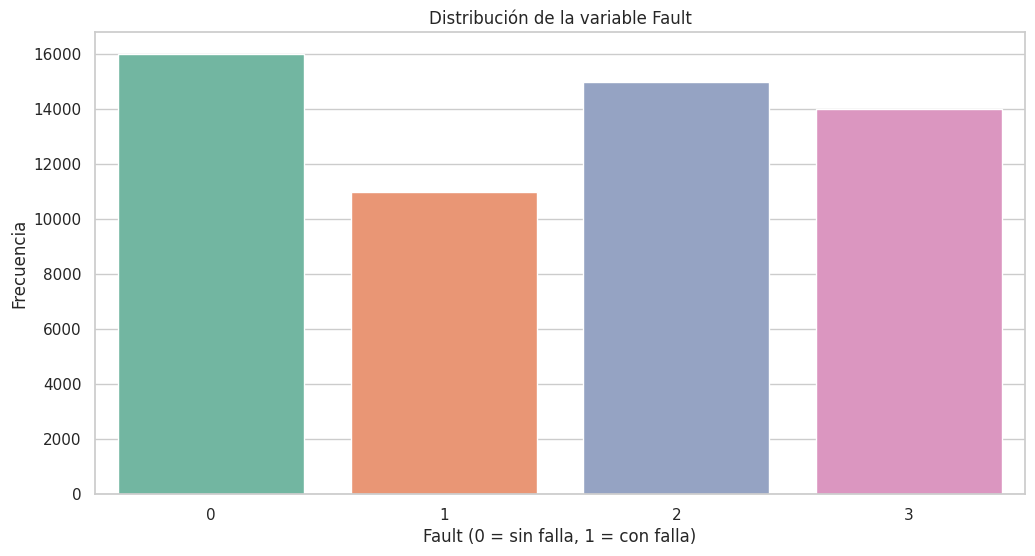

In [ ]:
print(df["Fault"].value_counts())
print("\nProporción:")
print(df["Fault"].value_counts(normalize=True))

sns.countplot(x="Fault", data=df, palette="Set2")
plt.title("Distribución de la variable Fault")
plt.xlabel("Fault (0 = sin falla, 1 = con falla)")
plt.ylabel("Frecuencia")
plt.show()

#**Distribucion de las variables**

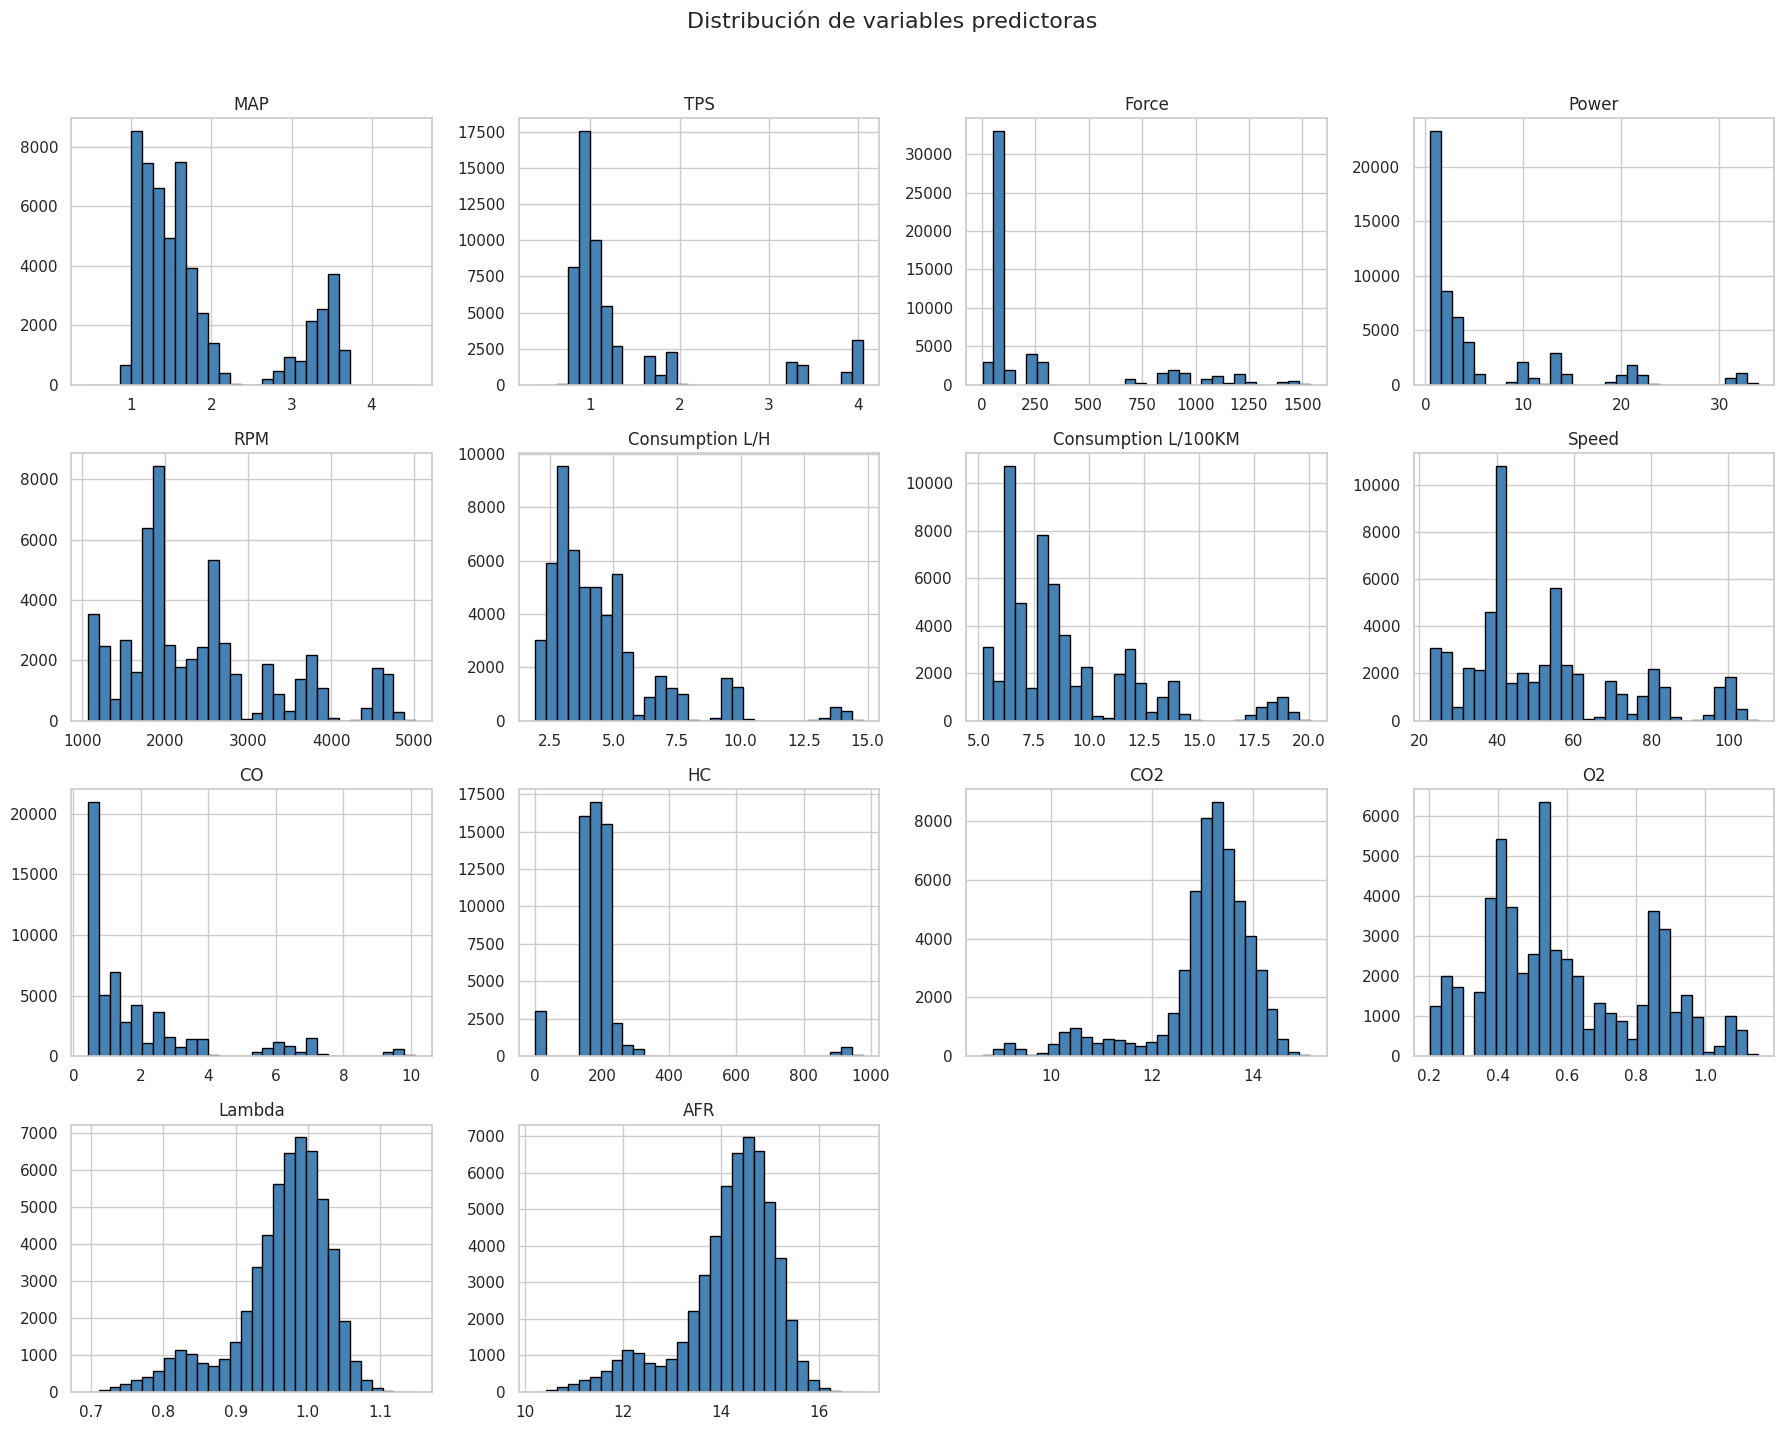

In [ ]:
columnas = df.columns.drop("Fault")

df[columnas].hist(bins=30, figsize=(18, 14), color="steelblue", edgecolor="black")
plt.suptitle("Distribución de variables predictoras", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

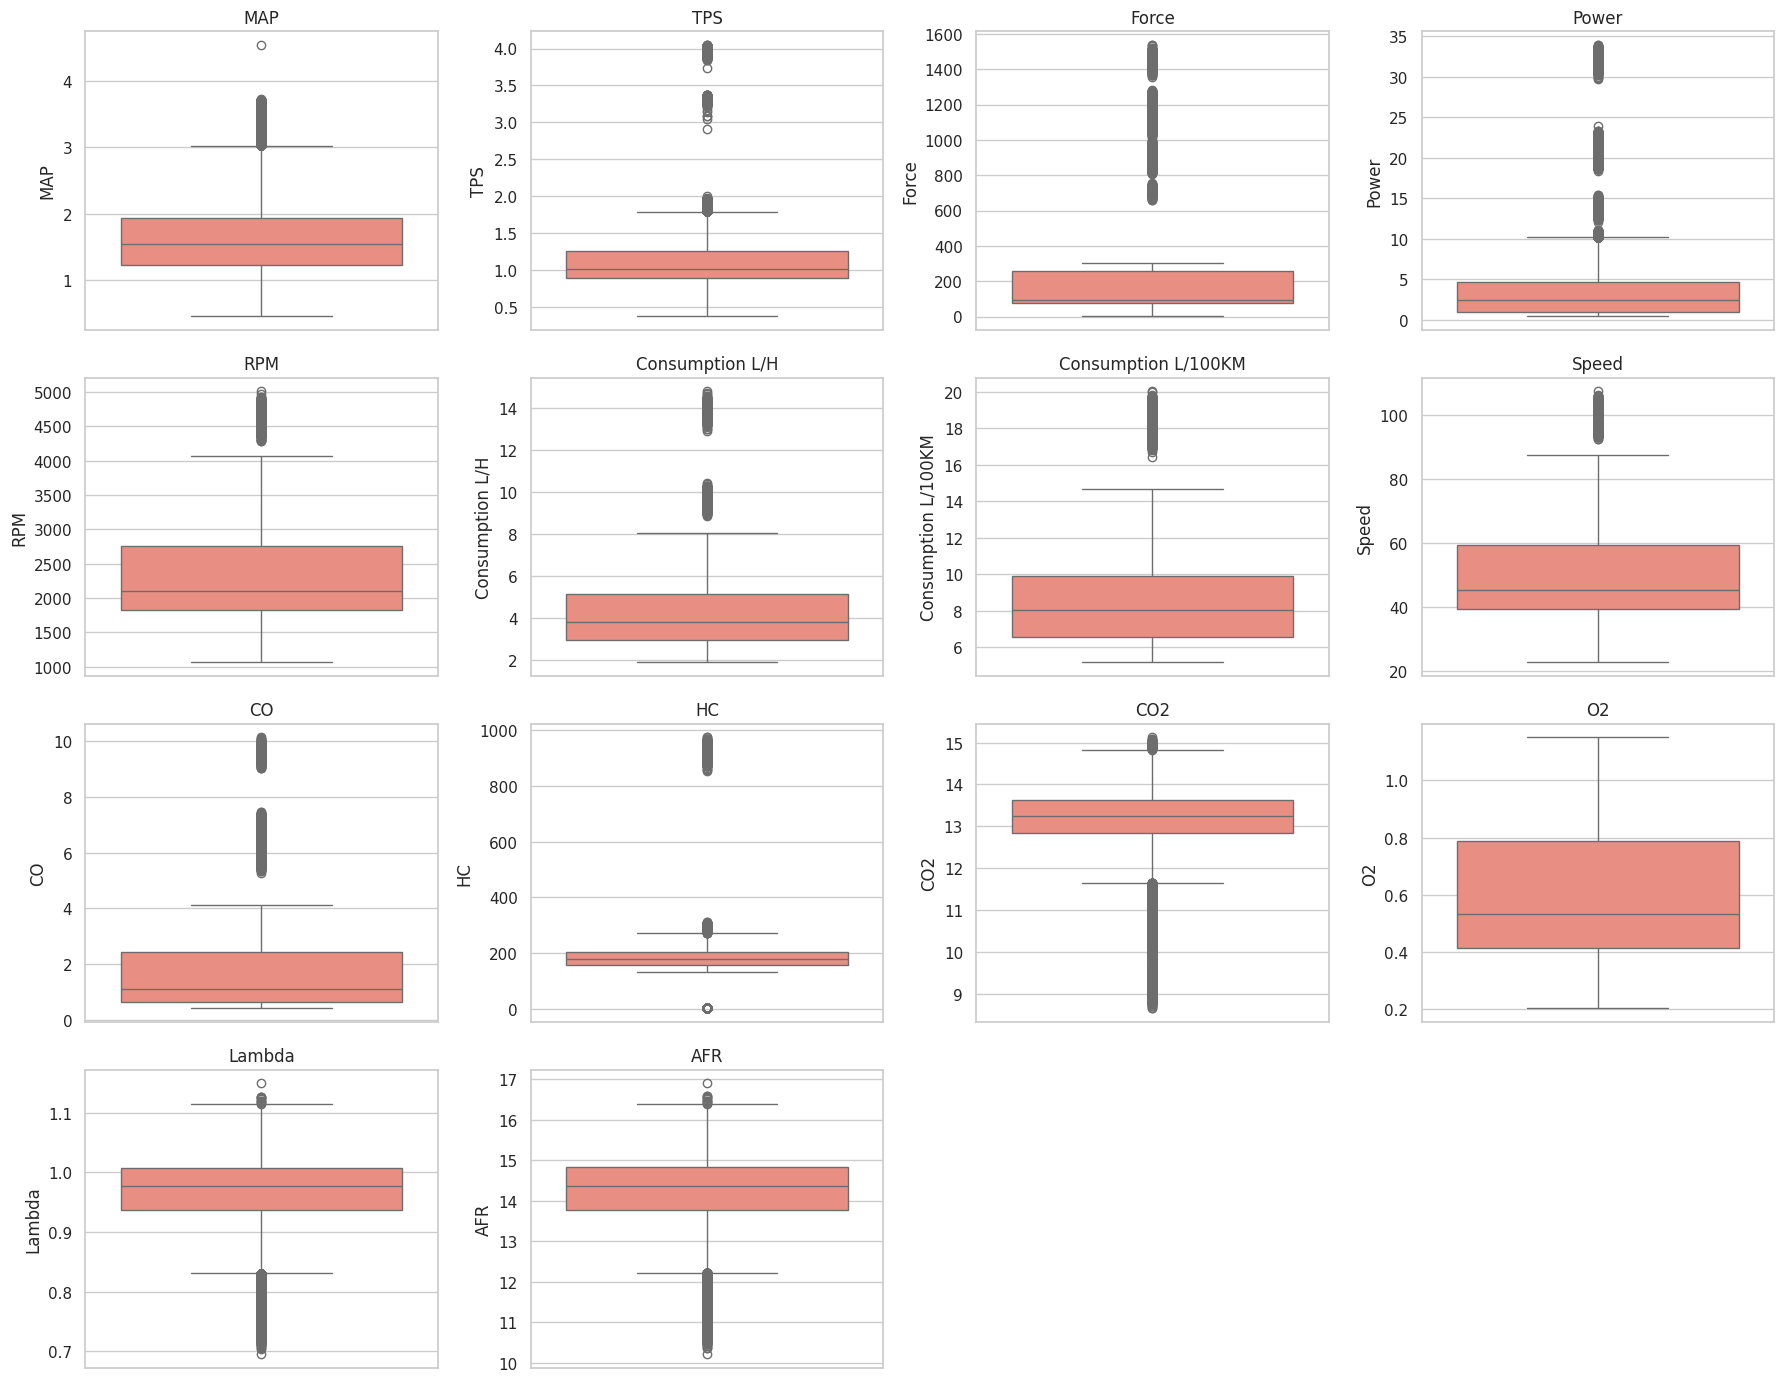

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(columnas):
    sns.boxplot(y=df[col], ax=axes[i], color="salmon")
    axes[i].set_title(col)

# Ocultar ejes sobrantes
for j in range(len(columnas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#**Matriz de correlacion**

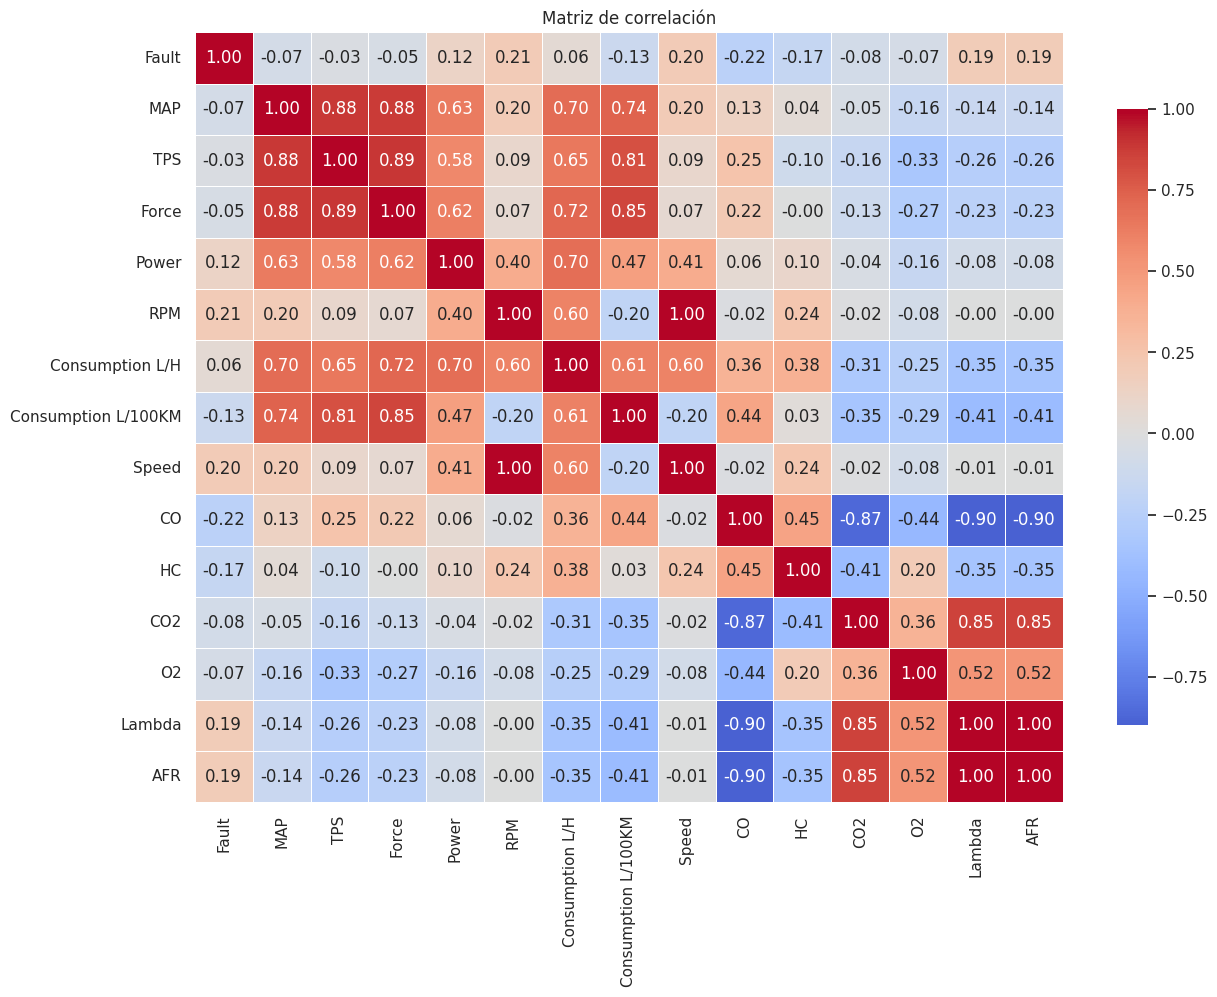

In [ ]:
plt.figure(figsize=(14, 10))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlación")
plt.show()

In [ ]:
corr_fault = df.corr(numeric_only=True)["Fault"].sort_values(ascending=False)
print(corr_fault)

Fault                  1.000000
RPM                    0.205279
Speed                  0.203806
AFR                    0.187584
Lambda                 0.187571
Power                  0.117879
Consumption L/H        0.056363
TPS                   -0.025270
Force                 -0.049601
O2                    -0.068178
MAP                   -0.072753
CO2                   -0.078492
Consumption L/100KM   -0.128618
HC                    -0.172228
CO                    -0.224785
Name: Fault, dtype: float64


#**Correlacion de las variables con la variable objetivo**

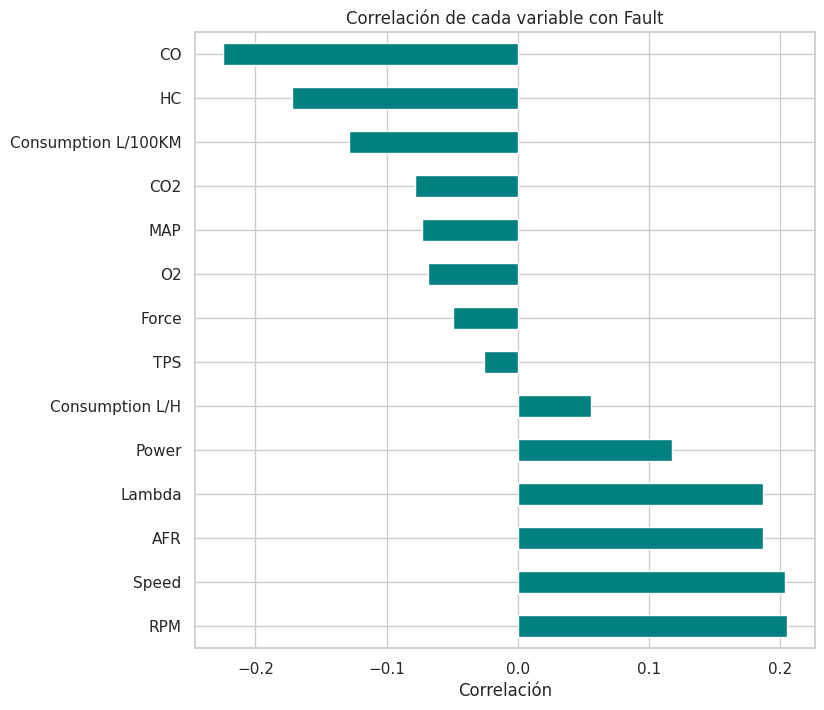

In [ ]:
plt.figure(figsize=(8, 8))
corr_fault.drop("Fault").plot(kind="barh", color="teal")
plt.title("Correlación de cada variable con Fault")
plt.xlabel("Correlación")
plt.show()

#**Comparación de las variables según la clase**

/tmp/ipykernel_4286/1022007316.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Fault", y=col, data=df, ax=axes[i], palette="Set3")
/tmp/ipykernel_4286/1022007316.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Fault", y=col, data=df, ax=axes[i], palette="Set3")
/tmp/ipykernel_4286/1022007316.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Fault", y=col, data=df, ax=axes[i], palette="Set3")
/tmp/ipykernel_4286/1022007316.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in 

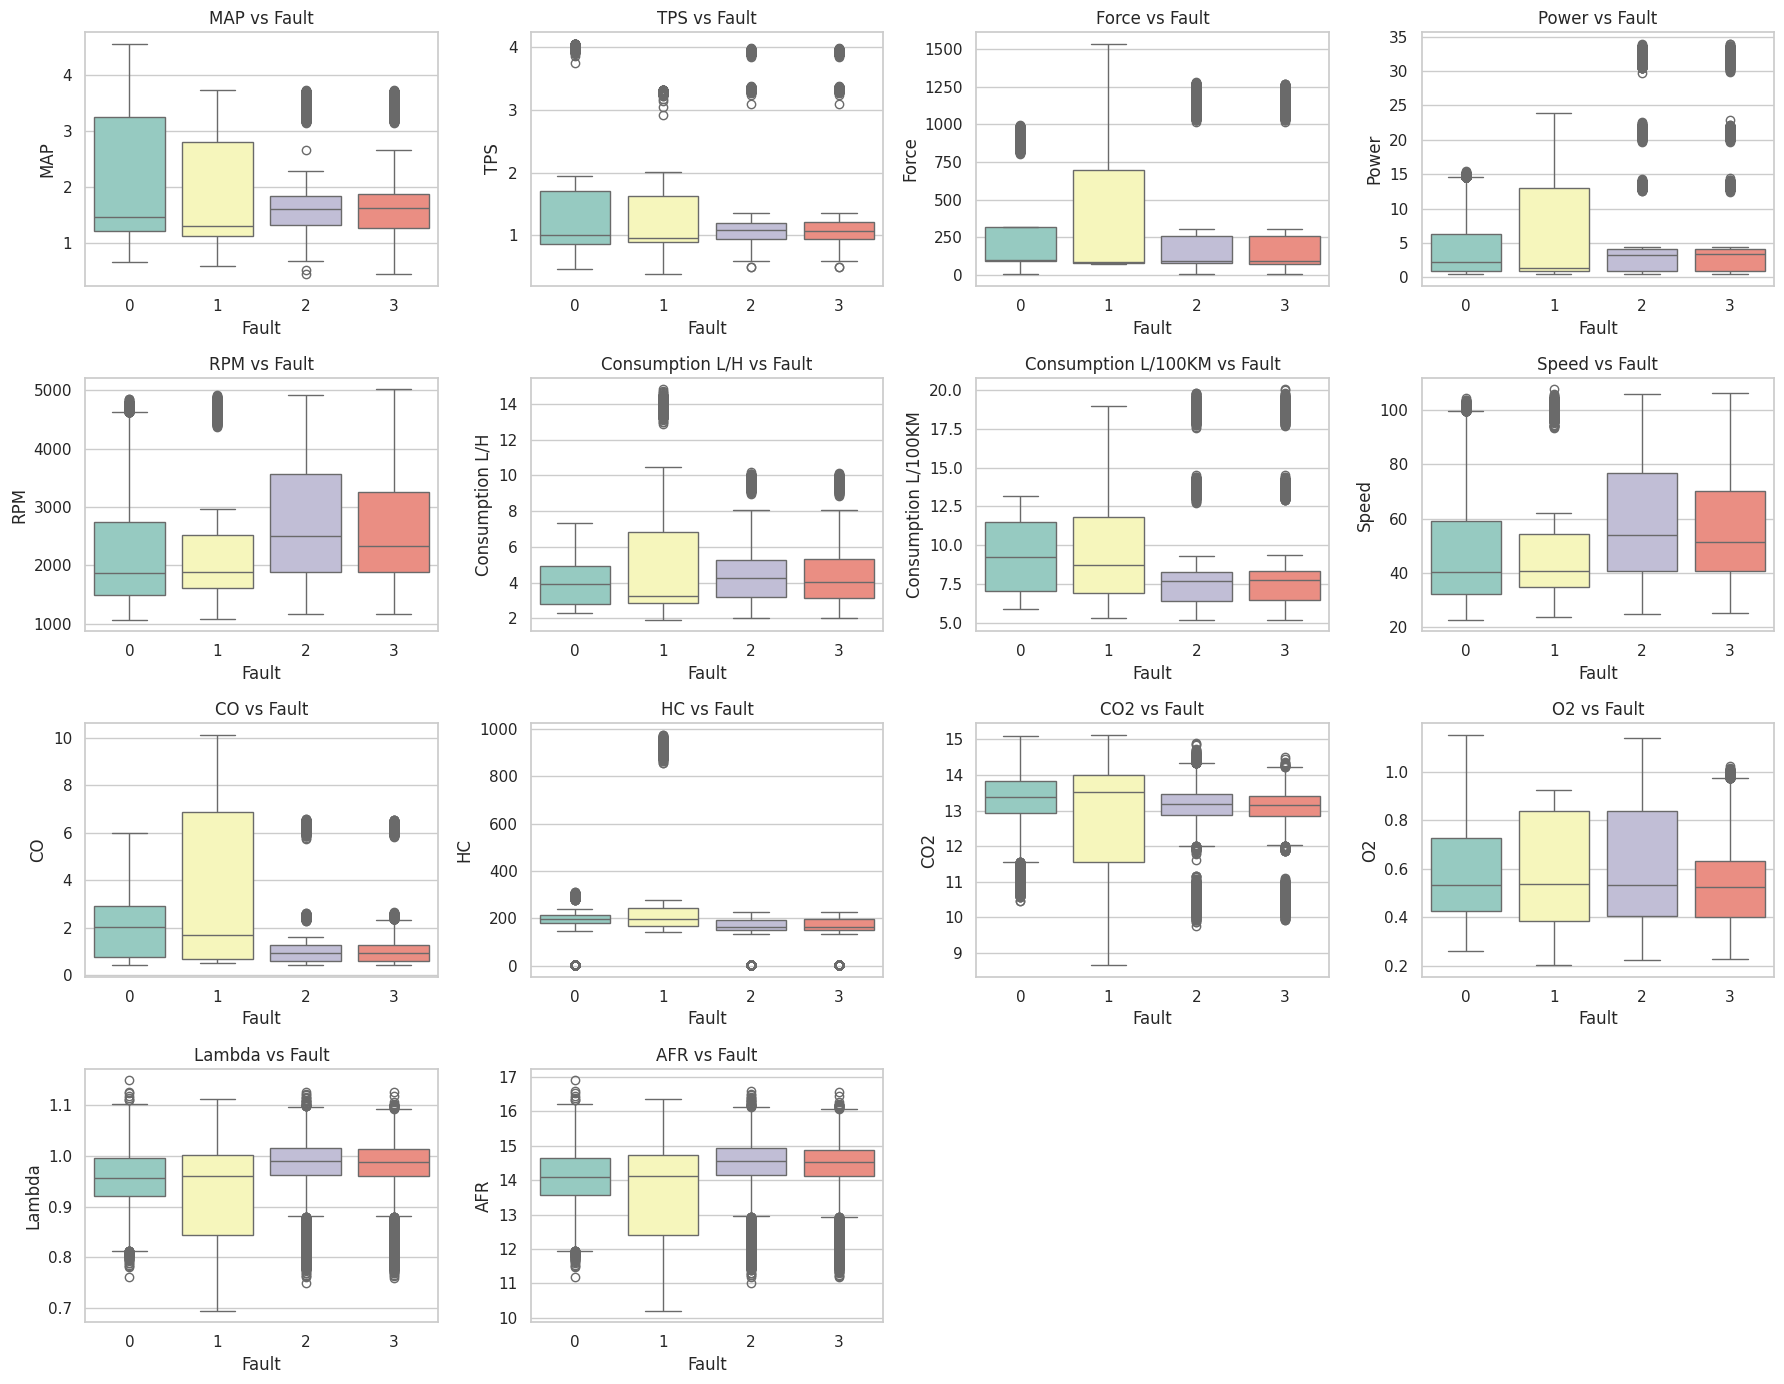

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(columnas):
    sns.boxplot(x="Fault", y=col, data=df, ax=axes[i], palette="Set3")
    axes[i].set_title(f"{col} vs Fault")

for j in range(len(columnas), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#**Deteccion valores atipicos**

In [ ]:
# Detección con IQR
def detectar_outliers(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[col] < lower) | (df[col] > upper)].shape[0]

outliers = {col: detectar_outliers(df, col) for col in columnas}
outliers_df = pd.DataFrame.from_dict(outliers, orient="index", columns=["n_outliers"])
outliers_df["%"] = (outliers_df["n_outliers"] / len(df)) * 100
print(outliers_df.sort_values("%", ascending=False))

                     n_outliers          %
Power                     11571  20.662869
Force                     11000  19.643208
MAP                       10533  18.809264
TPS                        9995  17.848533
CO                         6000  10.714477
CO2                        5980  10.678762
HC                         5006   8.939445
RPM                        4001   7.144770
Speed                      4001   7.144770
Consumption L/H            4000   7.142985
AFR                        3722   6.646547
Lambda                     3679   6.569760
Consumption L/100KM        3000   5.357239
O2                            0   0.000000


#**Pruebas estadisticas**

In [ ]:
from scipy.stats import ttest_ind, mannwhitneyu

resultados = []
for col in columnas:
    grupo0 = df[df["Fault"] == 0][col]
    grupo1 = df[df["Fault"] == 1][col]
    t_stat, p_val = ttest_ind(grupo0, grupo1, equal_var=False)
    resultados.append({"Variable": col, "t-stat": t_stat, "p-value": p_val})

resultados_df = pd.DataFrame(resultados).sort_values("p-value")
print(resultados_df)

               Variable     t-stat        p-value
9                    HC -33.669734  1.158371e-237
8                    CO -32.379479  6.960830e-222
10                  CO2  28.374370  1.731177e-172
5       Consumption L/H -28.386860  4.258206e-172
12               Lambda  27.707351  3.868872e-165
13                  AFR  27.706448  3.962486e-165
3                 Power -21.062567   3.993260e-97
0                   MAP  18.918256   2.830772e-79
1                   TPS  18.850645   9.325881e-79
6   Consumption L/100KM -16.952065   6.294338e-64
2                 Force -10.864452   2.029704e-27
4                   RPM  -7.411975   1.285989e-13
7                 Speed  -7.303044   2.902254e-13
11                   O2   2.316214   2.055545e-02
